# Lab 1: Intro to NumPy

## Preliminaries

**IMPORTANT NOTE: READ CAREFULLY**: On this lab, and generally on all asignments in this course, it is imperitive that your code exactly match specifications.  For instance, if you are asked to save the output in a variable named `output`, be sure that your results are saved in a variable whose name exactly matches `output` (e.g. not `Output`, `out put`, or `final_output`).  Similarly, if you are asked to create or fill in a function, the parameter count, order, data types, return types, etc must all match the specifications perfectly.  Your work, in part, will often be assessed with automated tests to help facilitate rapid feedback (including both tests you can see and tests you can't).  If these tests fail because you did not match specifications, you should expect no credit for those tests.  As a good sanity check, you should **never** have to modify test code unless explicitly stated.  You should also verify that your solutions work with any provided test code -- and you should probably write your own tests as you go!  Finally, please **DO NOT REMOVE** comments like `# BEGIN QUESTION 3` and make sure any work for a given question is strictly between the relevant `BEGIN` and `END` comments: some fancy regular expressions are being used in the background to identify your work for each question to help autograde it.

**NOTE:** Run the following cell to import libraries.  If you start working and come back later, you may need to rerun this cell to ensure that the libraries are loaded (and you may need to rerun some of your earlier cells to ensure that your variables are created)

**Information:**
- This lab is due Friday 1/30 at 5pm.  You will likely have time in class on Monday and Wednesday and will likely be able to work on questions 1 and 2 after Monday's lecture (and the rest, after Wednesday!)
- Each person should submit their own lab solo, but you are welcome to check work and bounce ideas with people near you as you go.  They should not, however, give you answers and you should not divide and conquer.
- It's OK to ask AI about syntax (e.g. 'explain to me how `ones` works in NumPy), but not to answer questions for you.  Since this lab is meant to teach you the syntax, try to learn it from the class notes and demos / links in the class notes, rather than just blindly googling.

In [59]:
import matplotlib.pyplot as plt
import random
import numpy as np 
import scipy.stats as stats 

## Question 1: Practice with Numpy Arrays

1a. First use Python list comprehensions to create a 6x6 python list `mylist` where the element `[i][j]` is `i*j`. 

In [60]:
# BEGIN QUESTION 1a
mylist = [[i*j for j in range(6)] for i in range (6)]

# END QUESTION 1a

# Sanity check tests
try:
    if type(mylist)==list and mylist[1][2]==mylist[2][1]==2 and len(mylist)==6:
        print("Public test for 1a passed")
    else:
        print("Public test for 1a FAILED")
except:
    print("Public test for 1a FAILED")


Public test for 1a passed


1b: First, convert mylist to a numpy array `myarray.`  Second, create a new array `subarray` where you extract just the even rows and just the odd columns (hint: see the Slice Notation section of our intro numpy notes!).  Here, the first row (row 0) is an even row, so as a sanity check, the first row of your slice should be `[0, 0, 0]`).  

In [61]:
# BEGIN QUESTION 1b
myarray = np.array(mylist)
subarray = myarray[::2, 1::2]
# END QUESTION 1b

# Sanity check tests
try:
    if type(subarray)==np.ndarray and subarray[0, 1]==subarray[0, 2]==0 and np.size(subarray)==9:
        print("Public test for 1b passed")
    else:
        print("Public test for 1b FAILED")
except:
    print("Public test for 1b FAILED")

Public test for 1b passed


1c: Run the first cell below.  This does exactly what you just did, but with lists: it creates a list `sublist` consisting of the even rows and odd columns of `mylist.'  Then it changes the top-left-most entry in sublist to 42 and finally prints both the modified sublist and original list.  Notice how nothing changes in the original list.

In [62]:
sublist = [[mylist[row][col] for col in [1, 3, 5]] for row in [0, 2, 4]]
print("Our sublist is: \n")
print(sublist)
print("\nChanging sublist[0][0] to 42...")
sublist[0][0]=42
print("Our sublist is now:\n")
print(sublist)

print("Our original list is:\n")
print(mylist)

Our sublist is: 

[[0, 0, 0], [2, 6, 10], [4, 12, 20]]

Changing sublist[0][0] to 42...
Our sublist is now:

[[42, 0, 0], [2, 6, 10], [4, 12, 20]]
Our original list is:

[[0, 0, 0, 0, 0, 0], [0, 1, 2, 3, 4, 5], [0, 2, 4, 6, 8, 10], [0, 3, 6, 9, 12, 15], [0, 4, 8, 12, 16, 20], [0, 5, 10, 15, 20, 25]]


Let's do the same experiment with our numpy array.  Write code to change the top-left-most entry in subarray to 42.  Then run the cell to see what happens to your original array, `myarray`.

In [63]:
# BEGIN QUESTION 1c
subarray[0, 0] = 42
# END QUESTION 1c
print(myarray)

[[ 0 42  0  0  0  0]
 [ 0  1  2  3  4  5]
 [ 0  2  4  6  8 10]
 [ 0  3  6  9 12 15]
 [ 0  4  8 12 16 20]
 [ 0  5 10 15 20 25]]


1d: Edit the markdown cell below to explain what is different between what you just did and the corresponding operation lists, relating your answer to views and copies as discussed in class.  If you wanted to create a subarray consiting of just the even rows and odd columns where changing the subarray did NOT change the original array, what would you have to change about your previous code?  Your answer should be 2-4 total sentences.

When slicing a NumPy array, the result is a view of the original array, not a copy, so modifying `subarray` also modifies `myarray`. In contrast, when creating `sublist` from `mylist`, Python created a new independent list, so changes to `sublist` don't affect `mylist`. To create a subarray that doesn't modify the original array, you would need to explicitly create a copy by adding `.copy()` to the slicing operation: `subarray = myarray[::2, 1::2].copy()`.

1e: Now write code to change the top-left-most entry in `mylist` and `myarray` to 42.5 (this should be two separate lines).  Then run the cell below to see what happens to both.

In [64]:
# BEGIN QUESTION 1e
mylist[0][0] = 42.5
myarray[0, 0] = 42.5
# END QUESTION 1e
print(mylist)
print(myarray)

[[42.5, 0, 0, 0, 0, 0], [0, 1, 2, 3, 4, 5], [0, 2, 4, 6, 8, 10], [0, 3, 6, 9, 12, 15], [0, 4, 8, 12, 16, 20], [0, 5, 10, 15, 20, 25]]
[[42 42  0  0  0  0]
 [ 0  1  2  3  4  5]
 [ 0  2  4  6  8 10]
 [ 0  3  6  9 12 15]
 [ 0  4  8 12 16 20]
 [ 0  5 10 15 20 25]]


1f: Edit the markdown cell below to explain the difference between what happened to your list and numpy array and explain why this occurs.  Your answer should be 1-2 total sentences.

The list `mylist` successfully stored the float value 42.5, while the NumPy array `myarray` truncated it to the integer 42. This occurs because `myarray` has an integer data type, so it automatically converts any assigned values to integers, whereas Python lists can store mixed types or any type without restriction.

## Question 2

In this question, we'll practice creating numpy arrays using a variety of methods.  It might help to review the sections on creating numpy arrays quickly and on miscelaneous other useful operations (specifically on stacking).  Our goal is to create a "striped flag" in three different ways.  Specifically, we want to create a 8x8 array where the middle two columns are all 1s and where the middle two rows are all 1s, but the rest of the entries are 0.

2a: Create a numpy array, `flag1`, where you make this striped flag by building a python list and then converting it to a Numpy array.  You can type out the full list directly, but it's probably faster and less tedious to think about list comprehensions or loops, etc.

In [65]:
# BEGIN QUESTION 2a
flaglist = [[1 if (i in [3, 4] or j in [3, 4]) else 0 for j in range(8)] for i in range(8)]
flag1 = np.array(flaglist)
# END QUESTION 2a


print(flag1)

# Sanity check tests
try:
    if type(flag1)==np.ndarray and np.sum(flag1)==28:
        print("Public test for 2a passed")
    else:
        print("Public test for 2a FAILED")
except:
    print("Public test for 2a FAILED")

[[0 0 0 1 1 0 0 0]
 [0 0 0 1 1 0 0 0]
 [0 0 0 1 1 0 0 0]
 [1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1]
 [0 0 0 1 1 0 0 0]
 [0 0 0 1 1 0 0 0]
 [0 0 0 1 1 0 0 0]]
Public test for 2a passed


2b: Create an identical numpy array, `flag2`, using only the following commands: np.hstack, np.vstack, np.ones, and np.zeros.  This could be a bit tedious and you may want to work your way up, but you can do it in 2 lines.  Hint: First use hstack to build the top 3 rows.

In [66]:
# BEGIN QUESTION 2b
top_rows = np.hstack([np.zeros((3, 3)), np.ones((3, 2)), np.zeros((3, 3))])
middle_rows = np.ones((2, 8))
flag2 = np.vstack([top_rows, middle_rows, top_rows])
# END QUESTION 2b

flag2

array([[0., 0., 0., 1., 1., 0., 0., 0.],
       [0., 0., 0., 1., 1., 0., 0., 0.],
       [0., 0., 0., 1., 1., 0., 0., 0.],
       [1., 1., 1., 1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1., 1., 1., 1.],
       [0., 0., 0., 1., 1., 0., 0., 0.],
       [0., 0., 0., 1., 1., 0., 0., 0.],
       [0., 0., 0., 1., 1., 0., 0., 0.]])

2c: Create an identical numpy array, `flag3`, starting from the all zeros array and using slicing (i.e. lines like `flag3[stuff:stuff, :]=1`) to modify the initial array.

In [67]:
# BEGIN QUESTION 2c
flag3 = np.zeros((8, 8))
flag3[3:5, :] = 1
flag3[:, 3:5] = 1
# END QUESTION 2c
flag3

array([[0., 0., 0., 1., 1., 0., 0., 0.],
       [0., 0., 0., 1., 1., 0., 0., 0.],
       [0., 0., 0., 1., 1., 0., 0., 0.],
       [1., 1., 1., 1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1., 1., 1., 1.],
       [0., 0., 0., 1., 1., 0., 0., 0.],
       [0., 0., 0., 1., 1., 0., 0., 0.],
       [0., 0., 0., 1., 1., 0., 0., 0.]])

## Question 3

In this question, we'll compare the speed of operations on python lists and on numpy in a simple application.  

Imagine that you are a bank running simulations.  You have a large number of accounts and want to forecast their value 10 years from now.  You will start by assuming each account grows at 7% interest per year.  For instance, if an account started with 100 dollars, its value in 10 years would be $100\times 1.07^{10}=196.71$ dollars.  And in general, if an account started with x dollars, its value in 10 years would be $x\times 1.06^{10}.$

3a: First write a function `future_value` that takes in a list of account values `mylist` and returns their value 10 years from now (assuming 7% interest per year).  You should NOT use numpy at this point.


In [68]:
# BEGIN QUESTION 3a
def future_value(mylist):
    return [x * (1.07 ** 10) for x in mylist]
# END QUESTION 3a
example = future_value([100, 200, 300])
print(example)

# Sanity check tests
try:
    if len(example)==3 and np.isclose(example[0], 196.715):
        print("Public test for 3a passed")
    else:
        print("Public test for 3a FAILED")
except:
    print("Public test for 3a FAILED")

[196.71513572895665, 393.4302714579133, 590.14540718687]
Public test for 3a passed


3b: Now write a function future_value_fast that works the same: it still takes in a list of account values now and returns their value 10 years from now (assuming 7% interest per year).  However, this time it should take advantage of numpy: the first step should be to convert the input `mylist` to a numpy array, and then directly use computations on numpy arrays (see the Computations on Arrays section of the notes).  It should return a numpy array.

In [69]:
# BEGIN QUESTION 3b
def future_value_fast(mylist):
    myarray = np.array(mylist)
    return myarray * (1.07 ** 10)

# END QUESTION 3b
example = future_value_fast([100, 200, 300])
print(example)

# Sanity check tests
try:
    if len(example)==3 and np.isclose(example[0], 196.715):
        print("Public test for 3b passed")
    else:
        print("Public test for 3b FAILED")
except:
    print("Public test for 3b FAILED")

[196.71513573 393.43027146 590.14540719]
Public test for 3b passed


3c: We called our second version fast.  Lets see if that's actually true!   Follow the template from our Motivating NumPy section experiment and write code (using `%timeit`) to time how long both `future_value` and `future_value_fast` take on a random list with 1,000,000 elements.  Hint: you only have to write two lines!!

In [70]:
size = 1000000
random.seed(42) # Will ensure that our experiments are the same
biglist = [random.randint(0, 1000) for thing in range(size)]
# BEGIN QUESTION 3c
%timeit future_value(biglist)
%timeit future_value_fast(biglist)
# END QUESTION 3c

127 ms ± 6.11 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)
92.2 ms ± 3.52 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


3d: Briefly describe the results.  Which method was faster?  By how much? 

`future_value_fast` is about 30% faster than `future_value`.

## Question 4

In the following question, you'll load in daily snowfall measurements at a (fake) ski mountain.  We'll do some MATH 216/227 style analysis on it -- this time, using numpy instead of R/ISLE!  However, there's one quirk in the data: on some days the sensor had an error resulting in missing data stored as np.nan. For this problem, assume that there is nothing systematic about the sensor errors (e.g. they're not more likely to occur on days with high snowfall).

First, run the following cell to load in the snow data.  Note that using np.median does not work because of the nans.

In [71]:
snow_data = np.array([0, 1.2, np.nan, 0, 8.2, 12.1, 0, 0.2, np.nan, 18.5, 0, 0, 2.1, 0, 32.0, 0, 8.2, 4.1, 0])

np.median(snow_data)

nan

4a: Use Numpy's NaN-safe functions which you can read about [here](https://jakevdp.github.io/PythonDataScienceHandbook/02.04-computation-on-arrays-aggregates.html#Other-aggregation-functions) to compute the 5 number summary.  Specifically, you should return a list of the form `[min, Q1, median, Q3, max]`.  For finding Q1/Q3, it might help to remember that Q1 is the 25th percentile...and that phrase percentile might clue in which numpy function to use!

In [72]:
# BEGIN QUESTION 4a
summary = [np.nanmin(snow_data), np.nanpercentile(snow_data, 25), np.nanmedian(snow_data), np.nanpercentile(snow_data, 75), np.nanmax(snow_data)]
# END QUESTION 4a
print(summary)

# Sanity check tests
try:
    if len(summary)==5 and np.isclose(summary[-1], 32):
        print("Public test for 4a passed")
    else:
        print("Public test for 4a FAILED")
except:
    print("Public test for 4a FAILED")

[0.0, 0.0, 0.2, 8.2, 32.0]
Public test for 4a passed


4b: Remember from MATH 216/227 that the `1.5 IQR` rule gives you a rule of thumb for detecting possible outliers: values that are either more than `1.5 * IQR` below Q1 or above Q3.  From the 5 number summary, we can see that there are no small outliers, but that there are high outliers. Update the following code cell and use numpy to count how many possible outliers are above the 1.5 IQR cutoff.  Hint: you may want to review the section of our numpy notes on using Boolean logic!

In [73]:
# BEGIN QUESTION 4b
IQR = summary[3] - summary[1]
cutoff = summary[3] + 1.5 * IQR
numoutliers = np.sum(snow_data > cutoff)
# END QUESTION 4b
print(numoutliers)

1


4c: The following code creates a boxplot of the data -- which should provide a sanity check on your answer to 4b!  Run the cell to see the boxplot.  Then write 1 sentence briefly explaining what `snow_data[~np.isnan(snow_data)]` does.

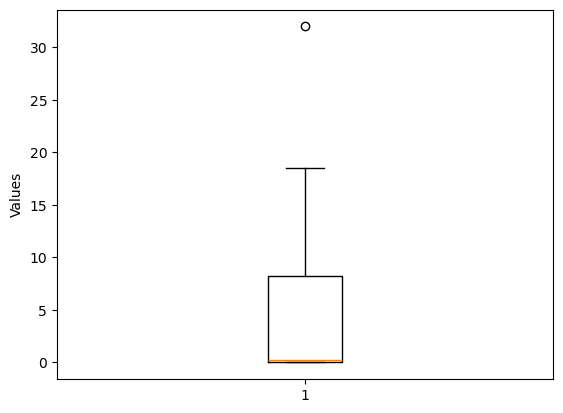

In [74]:
plt.boxplot(snow_data[~np.isnan(snow_data)])
plt.ylabel('Values')
plt.show()

The expression `snow_data[~np.isnan(snow_data)]` filters out the nan values from the `snow_data` array by using boolean indexing with the negation of the `isnan()` function, returning only the valid numerical snowfall measurements.

4d: Suppose we wanted to do inference about the mean.  From MATH 216/227, you might remember that this is a case of inference about the mean from a single population where the population standard deviation is unknown.  That puts us in the realm of a one-sample mean t hypothesis test/confidence interval.  Remember that the formula for a confidence interval is $$\bar{x} \pm t^* \frac{s}{\sqrt{n}}.$$  Fill in numpy code to get a 95% confidence interval for the true mean snowfall.

In [75]:

# BEGIN QUESTION 4d
conf_level = 0.95
cumulative_probability = 0.975 # A 95% CI "covers" the middle 95%, from 2.5% to 97.5%
degrees_of_freedom = np.sum(~np.isnan(snow_data)) - 1
t_star = stats.t.ppf(cumulative_probability, df=degrees_of_freedom)
xbar = np.nanmean(snow_data)
s = np.nanstd(snow_data, ddof=1)
n = np.sum(~np.isnan(snow_data))
low = xbar - t_star * s / np.sqrt(n)
high = xbar + t_star * s / np.sqrt(n)
# END QUESTION 4d
print(f"A 95% CI for the true mean snowfall ranges from {low} to {high}.")

A 95% CI for the true mean snowfall ranges from 0.588513152623876 to 9.599722141493771.


4e: But wait!  In MATH 216/227, hopefully it was drilled into you that you should always check conditions for inference first.  We didn't do that.  Use the code below to check conditions for inference.  Then write 1-2 sentences indicating whether or not the conditions for inference are met.

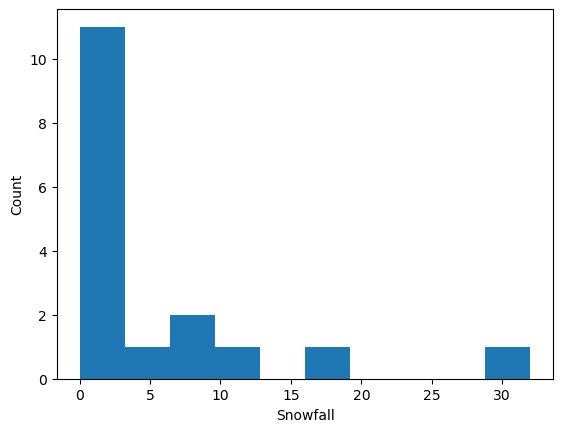

In [76]:
plt.hist(snow_data[~np.isnan(snow_data)])
plt.ylabel('Count')
plt.xlabel('Snowfall')
plt.show()

The histogram shows the distribution is somewhat right-skewed with the presence of outliers, which violates the normality assumption required for a one-sample t-test. However, with a sample size of n=17, the Central Limit Theorem provides some robustness to moderate departures from normality, though the presence of outliers is concerning and suggests the conditions for inference may not be fully met.

## Question 5

In this question, we'll work with and modify some bowling data!  The data below shows a set of scores from a bowling league.  Each row corresponds to a player and shows their score in each of 3 games.  For instance, the first player scored 150 points in their first game, 160 in their second, etc.  

5a: We need to fix our data! 
* The third player (whose first score was 120) is brand new and should have a 20 point handicap.
* We forgot to record our own data!  We scored 180 in the first game, 175 in the second, and 190 in the third.

Update scores to correctly reflect the data by (1) adding 20 to every game for the third player (using slice notation) and (2) adding our own data (using vstack).

In [77]:
scores = np.array([[150, 160, 155], [200, 190, 210], [120, 130, 110], [140, 145, 150]])
# BEGIN QUESTION 5a
scores[2, :] = scores[2, :] + 20
scores = np.vstack([scores, [180, 175, 190]])
# END QUESTION 5a
print(scores)

# Sanity check tests
try:
    if scores.size==15 and np.isclose(scores[-1, -1], 190):
        print("Public test for 5a passed")
    else:
        print("Public test for 5a FAILED")
except:
    print("Public test for 5a FAILED")

[[150 160 155]
 [200 190 210]
 [140 150 130]
 [140 145 150]
 [180 175 190]]
Public test for 5a passed


5b: Use numpy to compute the mean score for each player over their three games.  Do this in one line using np.mean (you might review the Computations over Dimensions section of our notes!)

In [78]:
# BEGIN QUESTION 5b
means = np.mean(scores, axis=1)
# END QUESTION 5b
print(means)

[155.         200.         140.         145.         181.66666667]


## Lab Check Hint for Lab 1

For your first lab check, you should feel good about:
- Basic syntax for NumPy arrays: creating an array from a list, accessing attributes like type, ndim, size, shape, and len
- Accessing and editing elements/slices in a NumPy array; views vs copies
- Building numPy arrays as in question 2 (using hstack, vstack, ones, and zeros)
- Understanding why NumPy computations are typically faster than list computations and what the implications of this are / how array and list operations might get different results (e.g. what you saw in Question 1).

For this lab check, I will not ask you to directly write NumPy code, but I may ask you about the output of NumPy code.

# Submission Instructions

We're going to try submitting this lab as a PDF, rather than a zip file.  Please carefully follow the instructions below.
1. Hit "Kernel --> Restart & Run All"
2. Make sure that all of your cells run and that any output necessary for grading is shown.  Be sure that you pass the provided tests.
3. Create a PDF of your notebook.  To do so, (1) hit File -> Download as -> HTML, (2) open that HTML file in Google Chrome (I drag from downloads into a new Chrome tab), and (3) save that HTML file as a PDF (I type `ctrl+P` to print and then select `Save as PDF` as my destination).  Note that this is a bit more involved than just saving as a PDF directly from Jupyter, but usually leads to better-formatted notebooks so **please follow this process exactly.**
4. Skim the PDF and make sure all your code and written responses are fully visible.  If you notice anything (like your code lines are too long and get cut off; your written answers are cut off), fix those issues and repeat the above process. If I cannot see your work, it will not be graded.
5. Upload that PDF to Gradescope.  If you run into any issues, please reach out to me before the deadline and document that you've completed everything (e.g. by emailing me a copy of your Jupyter notebook).